In [1]:
!pip install imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE 
from sklearn.model_selection import train_test_split

In [3]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.shape

(891, 12)

In [6]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

In [7]:
print( X.shape)
print(y.shape)

(891, 11)
(891,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (712, 11)
X_test : (179, 11)
y_train : (712,)
y_test : (179,)


In [10]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
df.shape

(891, 12)

In [12]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [13]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [14]:
missing_percentage = (df.isnull().sum() / len(df))*100
missing_percentage

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [15]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
print("Variables numériques :")
print(num_cols)

Variables numériques :
Index(['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


In [16]:
cat_cols = X.select_dtypes(include=["object"]).columns
print("Variables catégorielles :")
print(cat_cols)

Variables catégorielles :
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


In [17]:
X_train.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age            137
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          552
Embarked         2
dtype: int64

In [18]:
(X_train.isnull().sum() / len(X_train)) * 100

PassengerId     0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.241573
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.528090
Embarked        0.280899
dtype: float64

In [19]:
X_train = X_train.drop(columns=["Cabin"])
X_test = X_test.drop(columns=["Cabin"])

In [20]:
median_age = X_train["Age"].median()

X_train["Age"] = X_train["Age"].fillna(median_age)
X_test["Age"] = X_test["Age"].fillna(median_age)

In [21]:
X_train[["Age"]].isnull().sum()
X_test[["Age"]].isnull().sum()

Age    0
dtype: int64

In [22]:
mode_embarked = X_train["Embarked"].mode()[0]

X_train["Embarked"] = X_train["Embarked"].fillna(mode_embarked)
X_test["Embarked"] = X_test["Embarked"].fillna(mode_embarked)

In [23]:
X_train[X_train["Embarked"].isnull()]
X_test[X_test["Embarked"].isnull()]

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked


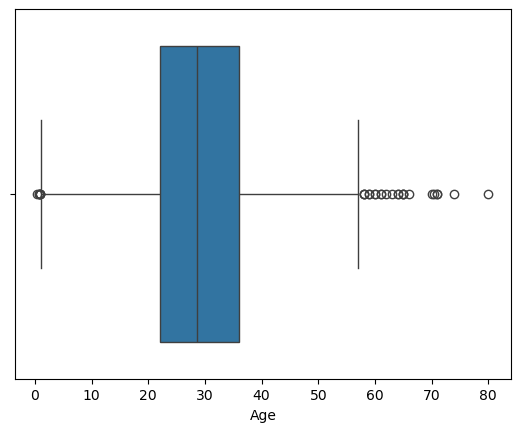

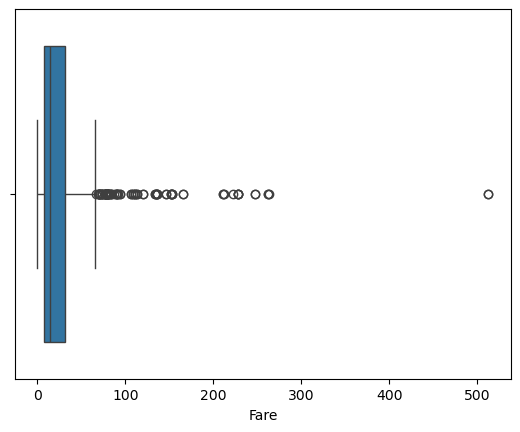

In [24]:
sns.boxplot(x=X_train["Age"])
plt.show()

sns.boxplot(x=X_train["Fare"])
plt.show()

In [25]:
Q1 = X_train["Age"].quantile(0.25)
Q3 = X_train["Age"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [26]:
median_age = X_train["Age"].median()

In [27]:
X_train["Age"] = X_train["Age"].mask(
    (X_train["Age"] < lower) | (X_train["Age"] > upper),
    median_age
)

In [28]:
outliers_restants = X_train[
    (X_train["Age"] < lower) |
    (X_train["Age"] > upper)
]
print("Nombre d'outliers restants :", len(outliers_restants))

Nombre d'outliers restants : 0


In [29]:
Q1 = X_train["Fare"].quantile(0.25)
Q3 = X_train["Fare"].quantile(0.75)
IQR = Q3 - Q1
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

In [30]:
median_fare = X_train["Fare"].median()
X_train["Fare"] = X_train["Fare"].mask(
    (X_train["Fare"] < borne_inf) | (X_train["Fare"] > borne_sup),
    median_fare
)

In [31]:
outliers_restants = X_train[
    (X_train["Fare"] < borne_inf) |
    (X_train["Fare"] > borne_sup)
]
print("Nombre d'outliers restants :", len(outliers_restants))

Nombre d'outliers restants : 0


In [32]:
cat_cols = X_train.select_dtypes(include=["object"]).columns
print(cat_cols)

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')


In [33]:
for col in cat_cols:
    print(col, ":", X_train[col].nunique(), "catégories")

Name : 712 catégories
Sex : 2 catégories
Ticket : 571 catégories
Embarked : 3 catégories


In [34]:
X_train = pd.get_dummies(X_train, columns=["Sex", "Embarked"])
X_test = pd.get_dummies(X_test, columns=["Sex", "Embarked"])

In [35]:
X_train.head()

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,693,3,"Lam, Mr. Ali",28.5,0,0,1601,56.4958,False,True,False,False,True
481,482,2,"Frost, Mr. Anthony Wood ""Archie""",28.5,0,0,239854,0.0000,False,True,False,False,True
527,528,1,"Farthing, Mr. John",28.5,0,0,PC 17483,14.4542,False,True,False,False,True
855,856,3,"Aks, Mrs. Sam (Leah Rosen)",18.0,0,1,392091,9.3500,True,False,False,False,True
801,802,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",31.0,1,1,C.A. 31921,26.2500,True,False,False,False,True


In [36]:
num_cols = ["Age", "SibSp", "Parch", "Fare"]

In [37]:
X_train[["SibSp", "Parch"]].nunique()

SibSp    7
Parch    7
dtype: int64

In [38]:
X_train[["SibSp", "Parch"]].apply(lambda x: x.unique())

,SibSp,Parch
0,0,0
1,1,1
2,8,2
3,3,5
4,4,3
5,2,4
6,5,6


In [39]:
X_train_avant = X_train.copy()
X_test_avant = X_test.copy()

In [40]:
scaler_minmax = MinMaxScaler()
X_train_normalise = X_train_avant.copy()
X_test_normalise = X_test_avant.copy()
X_train_normalise[num_cols] = scaler_minmax.fit_transform(X_train_avant[num_cols])
X_test_normalise[num_cols] = scaler_minmax.transform(X_test_avant[num_cols])

In [41]:
X_train_normalise[num_cols].agg(["min", "max"])

,Age,SibSp,Parch,Fare
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


In [42]:
scaler_standard = StandardScaler()
X_train_standardise = X_train_avant.copy()
X_test_standardise = X_test_avant.copy()
X_train_standardise[num_cols] = scaler_standard.fit_transform(X_train_avant[num_cols])
X_test_standardise[num_cols] = scaler_standard.transform(X_test_avant[num_cols])

In [44]:
X_train_standardise[num_cols].agg(["mean", "std"])

,Age,SibSp,Parch,Fare
mean,1.746418e-17,-5.613487e-18,-1.621674e-17,1.122697e-16
std,1.000703e+00,1.000703e+00,1.000703e+00,1.000703e+00


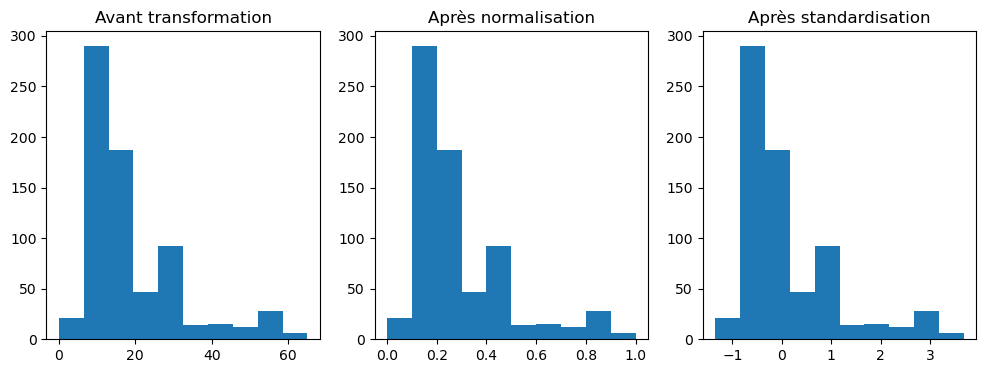

In [45]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.hist(X_train_avant["Fare"])
plt.title("Avant transformation")
plt.subplot(1, 3, 2)
plt.hist(X_train_normalise["Fare"])
plt.title("Après normalisation")
plt.subplot(1, 3, 3)
plt.hist(X_train_standardise["Fare"])
plt.title("Après standardisation")
plt.show()

In [46]:
X_train.head(10)

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,693,3,"Lam, Mr. Ali",28.5,0,0,1601,56.4958,False,True,False,False,True
481,482,2,"Frost, Mr. Anthony Wood ""Archie""",28.5,0,0,239854,0.0000,False,True,False,False,True
527,528,1,"Farthing, Mr. John",28.5,0,0,PC 17483,14.4542,False,True,False,False,True
855,856,3,"Aks, Mrs. Sam (Leah Rosen)",18.0,0,1,392091,9.3500,True,False,False,False,True
801,802,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",31.0,1,1,C.A. 31921,26.2500,True,False,False,False,True
652,653,3,"Kalvik, Mr. Johannes Halvorsen",21.0,0,0,8475,8.4333,False,True,False,False,True
509,510,3,"Lang, Mr. Fang",26.0,0,0,1601,56.4958,False,True,False,False,True
557,558,1,"Robbins, Mr. Victor",28.5,0,0,PC 17757,14.4542,False,True,True,False,False
828,829,3,"McCormack, Mr. Thomas Joseph",28.5,0,0,367228,7.7500,False,True,False,True,False
18,19,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",31.0,1,0,345763,18.0000,True,False,False,False,True


In [47]:
X_train_normalise.head(10)

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,693,3,"Lam, Mr. Ali",0.491071,0.000,0.000000,1601,0.869166,False,True,False,False,True
481,482,2,"Frost, Mr. Anthony Wood ""Archie""",0.491071,0.000,0.000000,239854,0.000000,False,True,False,False,True
527,528,1,"Farthing, Mr. John",0.491071,0.000,0.000000,PC 17483,0.222372,False,True,False,False,True
855,856,3,"Aks, Mrs. Sam (Leah Rosen)",0.303571,0.000,0.166667,392091,0.143846,True,False,False,False,True
801,802,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",0.535714,0.125,0.166667,C.A. 31921,0.403846,True,False,False,False,True
652,653,3,"Kalvik, Mr. Johannes Halvorsen",0.357143,0.000,0.000000,8475,0.129743,False,True,False,False,True
509,510,3,"Lang, Mr. Fang",0.446429,0.000,0.000000,1601,0.869166,False,True,False,False,True
557,558,1,"Robbins, Mr. Victor",0.491071,0.000,0.000000,PC 17757,0.222372,False,True,True,False,False
828,829,3,"McCormack, Mr. Thomas Joseph",0.491071,0.000,0.000000,367228,0.119231,False,True,False,True,False
18,19,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",0.535714,0.125,0.000000,345763,0.276923,True,False,False,False,True


In [48]:
X_train_standardise.head(10)

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,693,3,"Lam, Mr. Ali",-0.011427,-0.465084,-0.466183,1601,3.027097,False,True,False,False,True
481,482,2,"Frost, Mr. Anthony Wood ""Archie""",-0.011427,-0.465084,-0.466183,239854,-1.348827,False,True,False,False,True
527,528,1,"Farthing, Mr. John",-0.011427,-0.465084,-0.466183,PC 17483,-0.229266,False,True,False,False,True
855,856,3,"Aks, Mrs. Sam (Leah Rosen)",-0.965934,-0.465084,0.727782,392091,-0.624616,True,False,False,False,True
801,802,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",0.215836,0.478335,0.727782,C.A. 31921,0.684386,True,False,False,False,True
652,653,3,"Kalvik, Mr. Johannes Halvorsen",-0.693217,-0.465084,-0.466183,8475,-0.695620,False,True,False,False,True
509,510,3,"Lang, Mr. Fang",-0.238691,-0.465084,-0.466183,1601,3.027097,False,True,False,False,True
557,558,1,"Robbins, Mr. Victor",-0.011427,-0.465084,-0.466183,PC 17757,-0.229266,False,True,True,False,False
828,829,3,"McCormack, Mr. Thomas Joseph",-0.011427,-0.465084,-0.466183,367228,-0.748545,False,True,False,True,False
18,19,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",0.215836,0.478335,-0.466183,345763,0.045376,True,False,False,False,True


In [49]:
y_train.value_counts()

Survived
0    439
1    273
Name: count, dtype: int64

In [50]:
y_train.value_counts(normalize=True) * 100

Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64

In [51]:
!pip install imbalanced-learn

In [52]:
from imblearn.under_sampling import RandomUnderSampler
under = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = under.fit_resample(X_train, y_train)

In [53]:
y_train_under.value_counts()

Survived
0    273
1    273
Name: count, dtype: int64

In [57]:
X_train_smote_input = X_train.drop(columns=["Name", "Ticket"])

In [58]:
from imblearn.over_sampling import SMOTE

In [59]:
smote = SMOTE(random_state=42)

In [60]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_smote_input, y_train
)

In [61]:
y_train_smote.value_counts()

Survived
1    439
0    439
Name: count, dtype: int64